Before starting: download the data from Moodle (files too large for GitHub) and place it so that it matches the structure below.
The Moodle archive names the anatomical folder `T1w/`: rename it to `T1/`.

```code
NSSP-Mini-project-1
    /Project_notebook.ipynb
    /data
        /T1
            /T1w.nii.gz
        /fMRI
            /tfMRI_LANGUAGE_LR
                /tfMRI_LANGUAGE_LR_task_onsets.csv
                /tfMRI_LANGUAGE_LR.nii.gz
        /derivatives          <- created by this notebook (outputs + figures)
```

Requirements: FSL (`bet`, `fast`, `flirt` in the PATH, `FSLDIR` set) and the Python packages `nilearn`, `nibabel`, `antspyx`.

In [1]:
import os
import os.path as op
import shutil
import subprocess
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from nilearn import plotting # brain image plotting

# Data folder, relative to this notebook: works on every machine without editing
data_dir = op.abspath("data")


out_dir = op.join(data_dir, "derivatives")
out_anatomical_dir = op.join(out_dir, "anat")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(out_anatomical_dir, exist_ok=True)

t1_path = op.join(data_dir, "T1", "T1w.nii.gz") # original structural image
fig_dir = op.join(out_dir, "figures") # folder for the saved figures
os.makedirs(fig_dir, exist_ok=True)                 # create output folders (no error if they exist)
FIG_DPI = 300                                       # enough for the PDF report (1000 dpi gave 9000 px images)


# FSL environment
## REQUIRES FSL download (https://fsl.fmrib.ox.ac.uk/fsl/docs/install/index.html)
fsldir = os.environ.get("FSLDIR", op.expanduser("~/fsl"))  # FSL install folder (this is the default, change if needed)
os.environ["FSLDIR"] = fsldir                       # make sure FSL tools can find their files
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"            # FSL writes .nii.gz files
os.environ["PATH"] = os.pathsep.join([op.join(fsldir, "bin"), op.join(fsldir, "share", "fsl", "bin"), os.environ["PATH"]])

# MNI152 templates
mni_head = op.join(fsldir, "data", "standard", "MNI152_T1_1mm.nii.gz")        # whole-head template
mni_brain = op.join(fsldir, "data", "standard", "MNI152_T1_1mm_brain.nii.gz")  # skull-stripped template


assert op.exists(t1_path), f"T1w image not found: {t1_path}"
assert op.exists(out_anatomical_dir), f"Output directory not found: {out_anatomical_dir}"
assert op.exists(fig_dir), f"Output directory not found: {fig_dir}"
assert op.exists(mni_head), f"MNI template not found: {mni_head}"
assert op.exists(mni_brain), f"MNI template not found: {mni_brain}"
assert shutil.which("bet"), f"FSL tools not found in the PATH (FSLDIR={fsldir})"

print("All good. T1w:", t1_path)
print("FSL directory:", fsldir)

All good. T1w: /Users/valentinmarbach/Desktop/EPFL/MA1/NSSP/NSSP-Mini-project-1/data/T1/T1w.nii.gz
FSL directory: /Users/valentinmarbach/miniconda3/envs/neural_signal


## 1. skull-stripping with FSL BET

**Purpose.** Remove the skull, scalp and neck. Their intensities would bias the next steps: FAST models the voxel intensities as a mixture of tissues, and the registration maximises an intensity similarity with a skull-stripped template.

**Parameters.** `-R` (robust brain-centre estimation) and `-f 0.3`, which is more permissive than the default 0.5.

> **To decide as a group (review part1-review).** The annex below compares `-f 0.3` and `-f 0.5`.
> - 0.5 removes ~59 mL (1379 → 1322 mL), mostly at the base of the brain. FAST labels most of it as CSF/meninges (~47 mL) and ~11 mL as grey matter.
> - On the figure, 0.3 keeps small non-brain islands (orbit/sinus region at z = -30, sella turcica at x = 10).
> - 0.5 follows the cortex without visibly cutting the temporal poles or the cerebellum.
>
> Unless someone sees lost cortex on other slices, `-f 0.5` looks at least as good. Whichever value is chosen, the justification should be stated in the report.

In [2]:
brain_prefix = op.join(out_anatomical_dir, "T1w_brain") # BET output name (without extension)
brain = brain_prefix + ".nii.gz"                        # skull-stripped brain image
mask = brain_prefix + "_mask.nii.gz"                    # binary brain mask

# FSL BET: -R robust centre estimation, -f 0.3 threshold (see justification above), -m save mask
subprocess.run(["bet", t1_path, brain_prefix, "-R", "-f", "0.3", "-m"], check=True)

CompletedProcess(args=['bet', '/Users/valentinmarbach/Desktop/EPFL/MA1/NSSP/NSSP-Mini-project-1/data/T1/T1w.nii.gz', '/Users/valentinmarbach/Desktop/EPFL/MA1/NSSP/NSSP-Mini-project-1/data/derivatives/anat/T1w_brain', '-R', '-f', '0.3', '-m'], returncode=0)

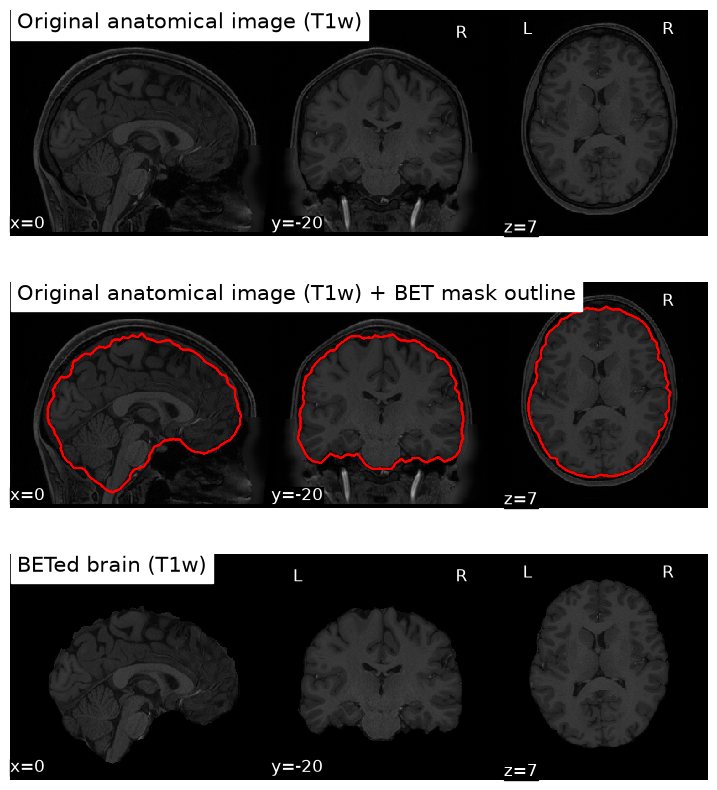

In [3]:
# Plotting results: same slices in every row, so that the rows can be compared
CUT = (0, -20, 7)
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

# subplot 1: original T1w
plotting.plot_anat(t1_path, axes=axs[0], cut_coords=CUT, draw_cross=False,
                   title="Original anatomical image (T1w)", colorbar=False)

# subplot 2: original T1w with the brain mask outline in red (to check the extraction quality)
ax = plotting.plot_anat(t1_path, axes=axs[1], cut_coords=CUT, draw_cross=False,
                        title="Original anatomical image (T1w) + BET mask outline", colorbar=False)
ax.add_contours(mask, colors="r", linewidths=1)  # draw the mask boundary

# subplot 3: betted brain
plotting.plot_anat(brain, axes=axs[2], cut_coords=CUT, draw_cross=False,
                   title="BETed brain (T1w)", colorbar=False)

fig.savefig(op.join(fig_dir, "1_skull_stripping_BET.png"), dpi=FIG_DPI)
plt.show()

### Annex: choice of the BET threshold `-f`

The same BET run with the default `-f 0.5`, to justify the choice of 0.3. Both outlines are drawn on a low slice, where the two masks differ most.

Brain mask volume  -f 0.3: 1379 mL   -f 0.5: 1322 mL


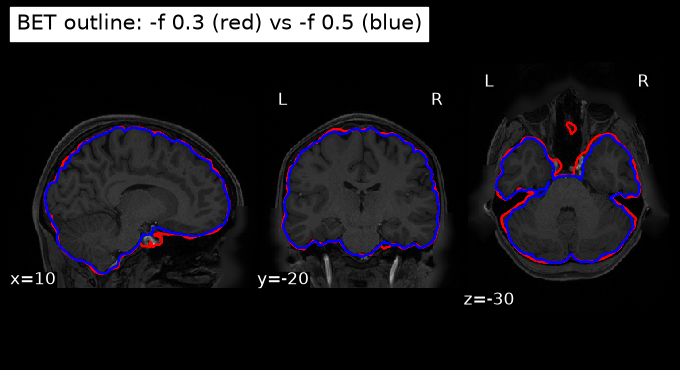

In [4]:
bet05_prefix = op.join(out_anatomical_dir, "T1w_brain_f05")
mask05 = bet05_prefix + "_mask.nii.gz"
subprocess.run(["bet", t1_path, bet05_prefix, "-R", "-f", "0.5", "-m"], check=True)

def volume_ml(img_path):
    """Volume (mL) of the non-zero voxels of an image."""
    img = nib.load(img_path)
    return (img.get_fdata() > 0).sum() * np.prod(img.header.get_zooms()[:3]) / 1000

print(f"Brain mask volume  -f 0.3: {volume_ml(mask):.0f} mL   -f 0.5: {volume_ml(mask05):.0f} mL")

d = plotting.plot_anat(t1_path, cut_coords=(10, -20, -30), draw_cross=False, colorbar=False,
                       title="BET outline: -f 0.3 (red) vs -f 0.5 (blue)")
d.add_contours(mask, colors="r", linewidths=1)
d.add_contours(mask05, colors="b", linewidths=1)
d.savefig(op.join(fig_dir, "annex_BET_threshold.png"), dpi=FIG_DPI)
plt.show()

## 2. tissue segmentation with FSL FAST

**Purpose.** Separate grey matter, white matter and CSF. This checks the anatomy, gives a grey-matter mask that restricts the fMRI analysis to where the BOLD signal comes from, and gives WM/CSF masks for nuisance regressors.

The tissue volumes printed below give a quantitative check of the segmentation, on top of the visual one.

In [5]:
# Run FAST (takes a few minutes)
fast_prefix = op.join(out_anatomical_dir, "T1w_brain_fast")
seg = fast_prefix + "_seg.nii.gz"       # hard labels: 1 = CSF, 2 = GM, 3 = WM

# FAST: -t 1 = T1 image, -n 3 = three tissue classes
subprocess.run(["fast", "-t", "1", "-n", "3", "-o", fast_prefix, brain], check=True)

# Tissue volumes from the partial-volume maps (pve_k = fraction of tissue k in each voxel)
voxel_ml = np.prod(nib.load(brain).header.get_zooms()[:3]) / 1000
for k, name in enumerate(["CSF", "Grey matter", "White matter"]):
    pve = nib.load(f"{fast_prefix}_pve_{k}.nii.gz").get_fdata()
    print(f"{name:13s}: {pve.sum() * voxel_ml:4.0f} mL")

CSF          :  229 mL
Grey matter  :  654 mL
White matter :  496 mL


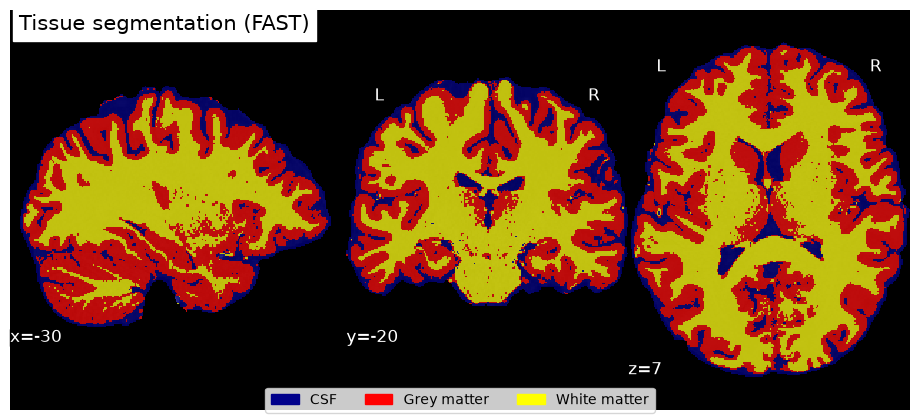

In [6]:
# Plotting the segmentation results
# x = -30: a lateral sagittal slice shows the cortical ribbon (x = 0 falls in the interhemispheric fissure)
fig = plt.figure(figsize=(9, 4))

plotting.plot_roi(seg, bg_img=brain, cut_coords=(-30, -20, 7), vmin=1, vmax=3,
                  cmap=ListedColormap(["darkblue", "red", "yellow"]),
                  alpha=0.7, colorbar=False, draw_cross=False, figure=fig,
                  title="Tissue segmentation (FAST)")



fig.legend(handles=[Patch(color="darkblue", label="CSF"),
                    Patch(color="red", label="Grey matter"),
                    Patch(color="yellow", label="White matter")],
           loc="lower center", ncol=3)

fig.savefig(op.join(fig_dir, "2_segmentation.png"), dpi=FIG_DPI)
plt.show()

## 3. registration to MNI space

**Purpose.** Bring the subject into a standard space. Activations can then be read with the coordinates and atlases of the literature (GLM questions 3e-f). The anatomy is also put into the space of the fMRI, which HCP provides already registered to MNI (*MNINonLinear*).

1. **FLIRT, linear, 12 DOF.** The matrix has scale factors of ~1.08 / 1.12 / 1.18 (the subject's brain is smaller than the template). A rigid 6-DOF transform could not absorb them, hence the 12-DOF affine.
2. **ANTs SyN, non-linear (as in lab 2).** The HCP fMRI was normalised non-linearly, so the T1 must be too. Otherwise the residual mismatches (ventricles, sulci) would come from the T1, and the anat-func overlay of step 2c would look misaligned. SyN takes a few seconds and clearly improves the match with the template (Dice and correlation printed below).

The SyN transform is also applied to the FAST segmentation (nearest neighbour, to keep integer labels). It gives the grey-matter mask in MNI space for the GLM.

Note: the native T1 is already AC-PC aligned by the HCP pipeline, with an origin close to MNI. This is why the "before" panel is already roughly centred.

In [7]:
affine_mat = op.join(out_anatomical_dir, "T1_to_MNI_flirt.mat") # linear transformation matrix (from FLIRT)
brain_flirt = op.join(out_anatomical_dir, "T1w_brain_MNI_FLIRT.nii.gz")

# FLIRT: linear registration (defaults written explicitly: 12 DOF affine, correlation ratio cost)
subprocess.run(["flirt", "-in", brain, "-ref", mni_brain, "-out", brain_flirt, "-omat", affine_mat,
                "-dof", "12", "-cost", "corratio"], check=True)
print("FLIRT matrix:\n", np.loadtxt(affine_mat).round(3))


# ANTs SyN: non-linear registration (lab 2), initialised by an affine step inside ants.registration
import ants
brain_syn = op.join(out_anatomical_dir, "T1w_brain_MNI_SyN.nii.gz")
seg_mni = op.join(out_anatomical_dir, "T1w_brain_fast_seg_MNI_SyN.nii.gz")

mni_ants = ants.image_read(mni_brain)
tx = ants.registration(fixed=mni_ants, moving=ants.image_read(brain), type_of_transform="SyN")
ants.image_write(tx["warpedmovout"], brain_syn)

# same transform applied to the tissue labels (nearest neighbour keeps the labels 1/2/3)
seg_warped = ants.apply_transforms(fixed=mni_ants, moving=ants.image_read(seg),
                                   transformlist=tx["fwdtransforms"], interpolator="nearestNeighbor")
ants.image_write(seg_warped, seg_mni)


def match_with_mni(img_path):
    """Intensity correlation and Dice of the brain masks between an image and the MNI brain template."""
    x = nib.load(img_path).get_fdata()
    m = nib.load(mni_brain).get_fdata()
    union = (x > 0) | (m > 0)
    corr = np.corrcoef(x[union], m[union])[0, 1]
    dice = 2 * ((x > 0) & (m > 0)).sum() / ((x > 0).sum() + (m > 0).sum())
    return corr, dice

reg_scores = {name: match_with_mni(p) for name, p in [("FLIRT", brain_flirt), ("SyN", brain_syn)]}
for name, (corr, dice) in reg_scores.items():
    print(f"{name:5s}: correlation with MNI = {corr:.3f}   Dice = {dice:.3f}")

FLIRT matrix:
 [[ 1.0760e+00 -1.5000e-02  1.2000e-02 -6.2590e+00]
 [ 2.3000e-02  1.1190e+00 -3.0000e-03 -1.6189e+01]
 [-2.2000e-02 -1.1000e-02  1.1810e+00 -7.9530e+00]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]]


FLIRT: correlation with MNI = 0.796   Dice = 0.923
SyN  : correlation with MNI = 0.855   Dice = 0.960


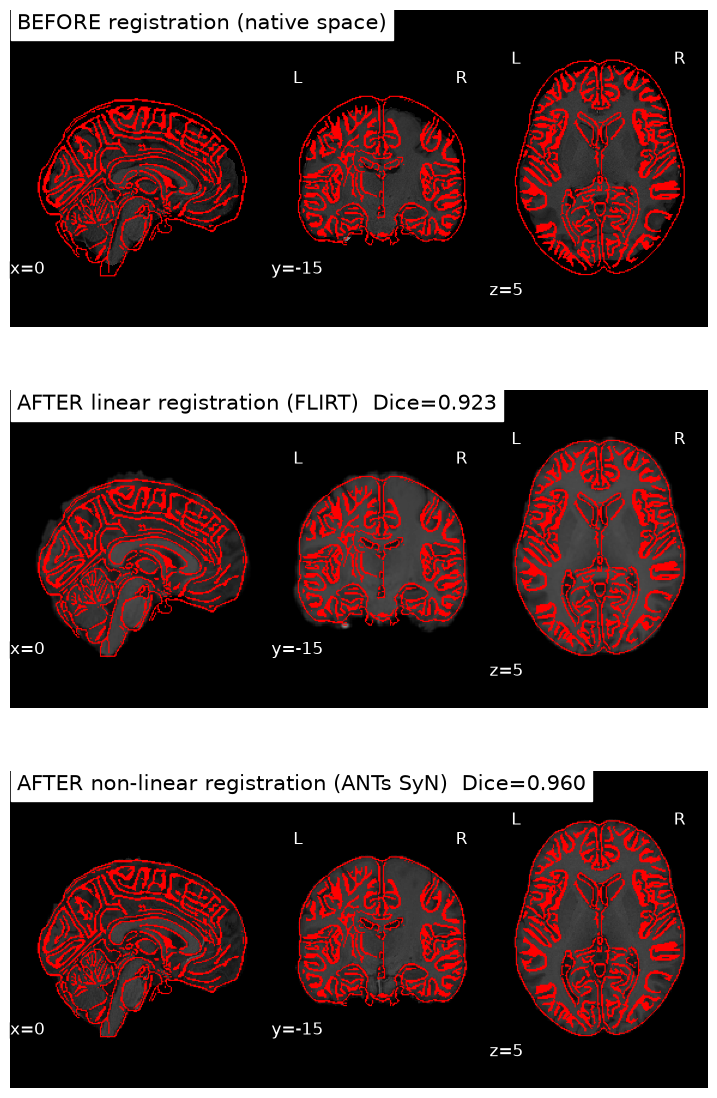

In [8]:
# Plotting pre- and post-registration results, same slices in every panel
CUT_MNI = (0, -15, 5)
fig, axs = plt.subplots(3, 1, figsize=(9, 14))

d = plotting.plot_anat(brain, axes=axs[0], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title="BEFORE registration (native space)")
d.add_edges(mni_brain, color="r") # MNI edges on top

corr, dice = reg_scores["FLIRT"]
d = plotting.plot_anat(brain_flirt, axes=axs[1], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER linear registration (FLIRT)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")

corr, dice = reg_scores["SyN"]
d = plotting.plot_anat(brain_syn, axes=axs[2], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER non-linear registration (ANTs SyN)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")


fig.savefig(op.join(fig_dir, "3_registration_MNI.png"), dpi=FIG_DPI)
plt.show()